In [ ]:
# import packages
import pandas as pd
import requests
import os
from dotenv import load_dotenv
from matplotlib import pylab as plt
import seaborn as sns
import ast
import numpy as np

In [25]:
# construct the API request
load_dotenv()
request_params = {
    'api_key': os.getenv('API_KEY'),
    'limit': 4000
}

api_url = 'https://developer.nps.gov/api/v1/thingstodo'
response = requests.get(api_url, params = request_params)

# check the API response
if response.status_code == 200:
    todo_data = response.json()
else:
    print(f'Response Code: {response.status_code}')
    print(f'Error Message: {response.text}')
    raise ValueError('Unsuccessful Request')


In [3]:
# save the data
selected_columns = [
    'doFeesApply',
    'isReservationRequired',
    'arePetsPermitted', 
    'tags', 
    'topics',   
    'timeOfDay',  
    'season',  
    'relatedParks',  
]

raw_todo_df = pd.DataFrame(todo_data['data'])
raw_todo_df.to_csv('../data/raw_todo.csv', index = False)
selected_todo_df = raw_todo_df[selected_columns].copy()
selected_todo_df.to_csv('../data/selected_todo.csv', index = False)


In [4]:
# count missing values for each column
for col in selected_todo_df.columns:
    if selected_todo_df[col].dtype == 'object':
        missing_count = sum(selected_todo_df[col].astype(str) == '[]')
        print(f'{col}: {missing_count} missing values')
    else:
        missing_count = sum(selected_todo_df[col] == '')
        print(f'{col}: {missing_count} missing values')

doFeesApply: 0 missing values
isReservationRequired: 0 missing values
arePetsPermitted: 0 missing values
tags: 338 missing values
topics: 0 missing values
timeOfDay: 801 missing values
season: 540 missing values
relatedParks: 112 missing values


In [5]:
eda_todo_df = selected_todo_df.copy()

# convert tags and topics to their lengths
for col in ['tags', 'topics']:
    eda_todo_df[col] = eda_todo_df[col].apply(lambda x: len(x) if isinstance(x, list) else 0)


In [6]:
# extract states from relatedParks and map to regions
region_map = {
    # Northeast 
    'CT': 'Northeast', 'ME': 'Northeast', 'MA': 'Northeast', 'NH': 'Northeast', 
    'RI': 'Northeast', 'VT': 'Northeast', 'NJ': 'Northeast', 'NY': 'Northeast', 'PA': 'Northeast',
    
    # Midwest 
    'IL': 'Midwest', 'IN': 'Midwest', 'MI': 'Midwest', 'OH': 'Midwest', 'WI': 'Midwest',
    'IA': 'Midwest', 'KS': 'Midwest', 'MN': 'Midwest', 'MO': 'Midwest', 'NE': 'Midwest', 
    'ND': 'Midwest', 'SD': 'Midwest',
    
    # South 
    'DE': 'South', 'DC': 'South', 'FL': 'South', 'GA': 'South', 'MD': 'South', 
    'NC': 'South', 'SC': 'South', 'VA': 'South', 'WV': 'South', 'AL': 'South', 
    'KY': 'South', 'MS': 'South', 'TN': 'South', 'AR': 'South', 'LA': 'South', 
    'OK': 'South', 'TX': 'South',
    
    # West 
    'AZ': 'West', 'CO': 'West', 'ID': 'West', 'MT': 'West', 'NV': 'West', 
    'NM': 'West', 'UT': 'West', 'WY': 'West', 'AK': 'West', 'CA': 'West', 
    'HI': 'West', 'OR': 'West', 'WA': 'West',

    # Territories 
    'PR': 'Territories', 
    'VI': 'Territories', 
    'GU': 'Territories', 
    'AS': 'Territories', 
    'MP': 'Territories'  
}

eda_todo_df['regions'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        region_map[state.strip()]
        for park in (val or [])       
        for state in str(park.get('states', '')).split(',')
    })
)


In [7]:
# extract designations from relatedParks and categorize parks
eda_todo_df['designations'] = eda_todo_df['relatedParks'].apply(
    lambda val: sorted({
        park.get('designation')
        for park in (val or [])
        if park.get('designation')  
    })
)

def categorize_park(name):
    name = str(name).strip()

    if name in [
        'National Park', 'National Parks',
        'National and State Parks', 'National Park & Preserve'
    ]:
        return 'National_Park'
    
    elif any(x in name for x in [
        'Historical', 'Historic', 'International Historic'
    ]):
        return 'Historical_Site'
    
    elif any(x in name for x in [
        'Monument', 'Memorial', 'Battlefield', 'Military Park'
    ]):
        return 'National_Monument'
    
    elif any(x in name for x in [
        'Recreation', 'Parkway', 'Lakeshore', 'Seashore'
    ]):
        return 'Recreation_Area'
    
    else:
        return 'Other_Protected_Area'


eda_todo_df['park_categories'] = eda_todo_df['designations'].apply(
    lambda des_list: sorted({
        categorize_park(des)        
        for des in (des_list or [])
    })
)



In [8]:
# convert columns to string type
for col in ['timeOfDay', 'season', 'regions', 'park_categories']:
    eda_todo_df[col] = eda_todo_df[col].astype(str)

# convert boolean columns to True/False
for col in ['isReservationRequired', 'arePetsPermitted', 'doFeesApply']:
    eda_todo_df[col] = eda_todo_df[col].map({'true': True, 'false': False})



In [9]:
# drop the original columns and save the EDA dataframe to a CSV file
eda_todo_df = eda_todo_df.drop(columns = ['relatedParks', 'designations'])
eda_todo_df.to_csv('../data/eda_todo.csv', index = False)

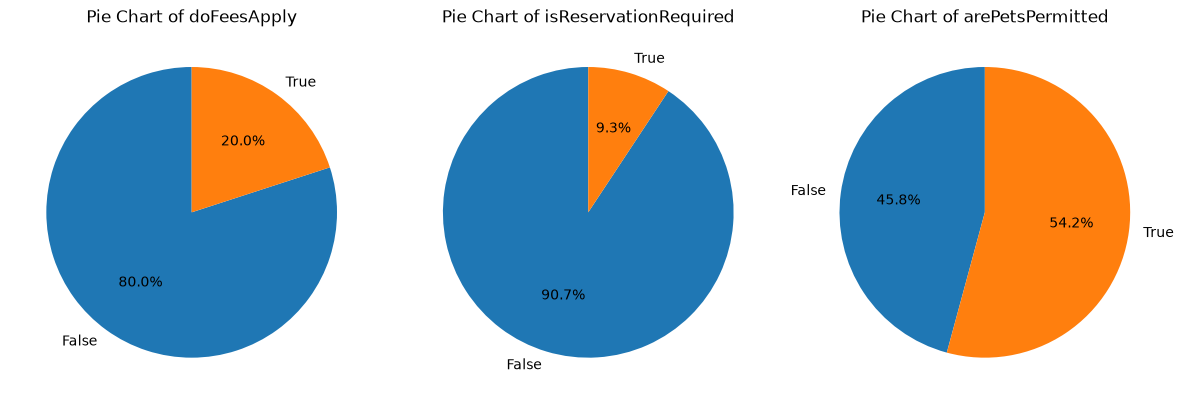

In [10]:
# create pie charts for doFeesApply, isReservationRequired, and arePetsPermitted
pie_cols = ['doFeesApply', 'isReservationRequired', 'arePetsPermitted']

fig, axes = plt.subplots(1, 3, figsize = (12, 6))
for ax, col in zip(axes, pie_cols):
   counts = eda_todo_df[col].value_counts().sort_index()
   ax.pie(counts, labels = counts.index, autopct = '%1.1f%%', startangle = 90)
   ax.set_title(f'Pie Chart of {col}')

plt.savefig('../figures/pie_charts.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

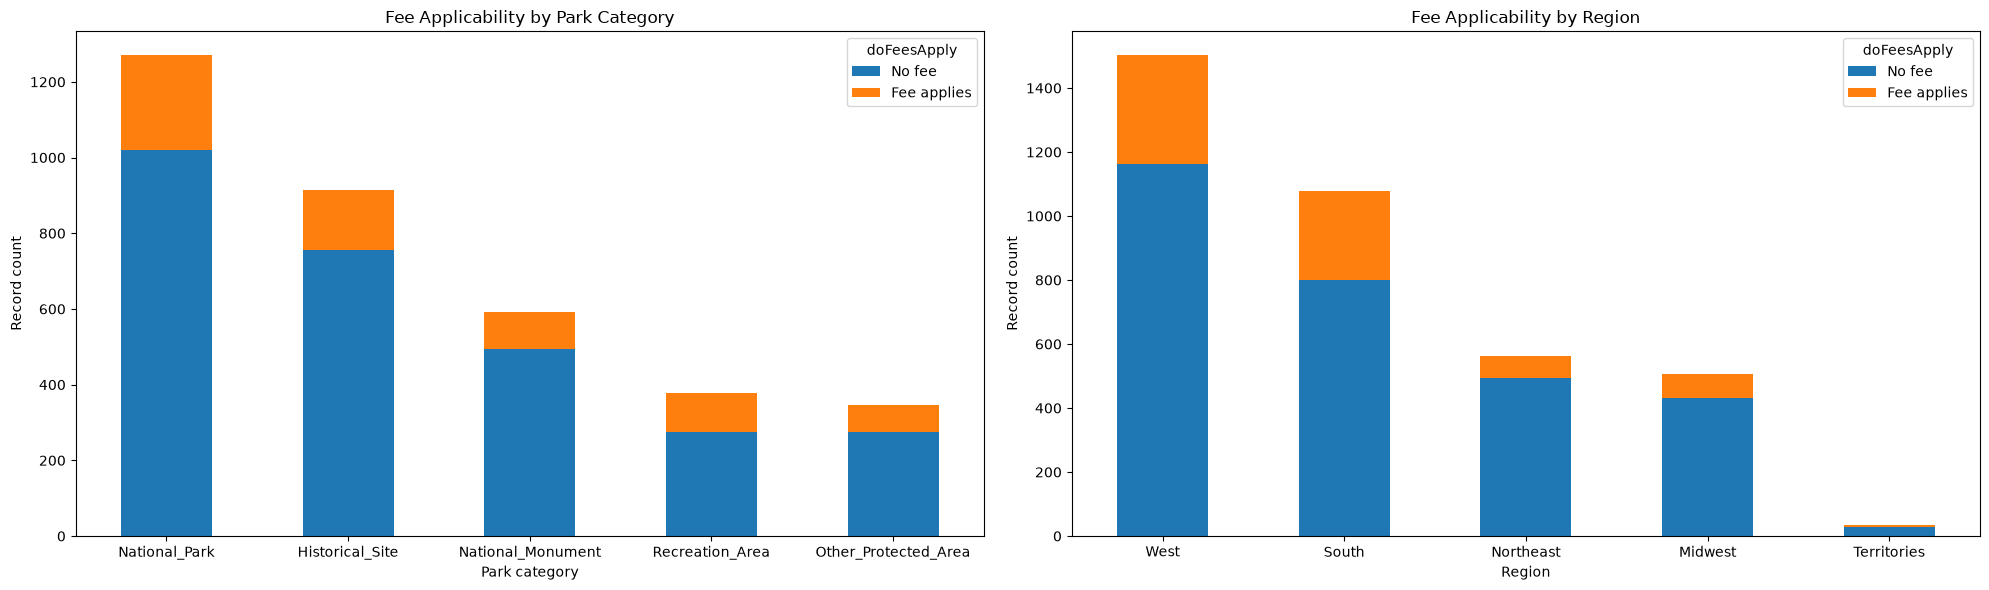

In [11]:
# Draw the stacked bar plot between each park category (left) / region (right) and fee requirement
park_categories = ['National_Park', 'Historical_Site', 'National_Monument', 'Recreation_Area', 'Other_Protected_Area']
regions = ['West', 'South', 'Northeast', 'Midwest', 'Territories']

def fee_counts_by_label(column, labels):
    parsed = eda_todo_df[column].apply(
        lambda value: ast.literal_eval(value)
        if isinstance(value, str) and value.strip()
        else value if isinstance(value, (list, tuple, set)) else []
    )
    return pd.DataFrame(
            {
                name: [
                    ((eda_todo_df["doFeesApply"].eq(fee)) & parsed.apply(lambda values: label in values)).sum()
                    for label in labels
                ]
                for fee, name in [(False, 'No fee'), (True, 'Fee applies')]
            },
            index = labels,
        )

park_counts = fee_counts_by_label('park_categories', park_categories)
region_counts = fee_counts_by_label('regions', regions)

fig, axes = plt.subplots(1, 2, figsize = (20, 6))

for ax, counts, title, xlabel in [
    (axes[0], park_counts, 'Fee Applicability by Park Category', 'Park category'),
    (axes[1], region_counts, 'Fee Applicability by Region', 'Region')
]:
    counts.plot(
        kind = 'bar', stacked = True, ax = ax, legend = False,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Record count')
    ax.tick_params(axis = 'x', rotation = 0)

axes[0].legend(title = 'doFeesApply')
axes[1].legend(title = 'doFeesApply')

plt.savefig('../figures/fee_applicability.png', dpi = 150, bbox_inches = 'tight')
fig.tight_layout()
plt.show()

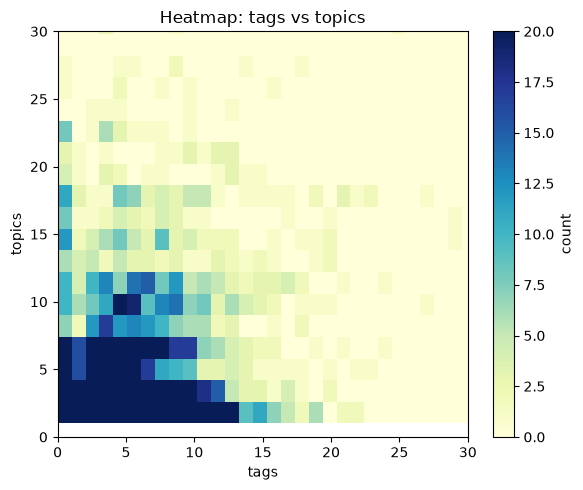

In [21]:
# Create a heatmap to visualize the relationship between tags and topics
nbins = 50  
heatmap, xedges, yedges = np.histogram2d(eda_todo_df['tags'], eda_todo_df['topics'], bins = nbins)

plt.figure(figsize = (6, 5))

plt.imshow(heatmap.T, origin = 'lower', aspect = 'auto', cmap = 'YlGnBu', vmax = 20, 
           extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]])

plt.colorbar(label = 'count')
plt.xlabel('tags')
plt.ylabel('topics')
plt.title('Heatmap: tags vs topics')
plt.xlim(0, 30)
plt.ylim(0, 30)

plt.savefig('../figures/heatmap.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

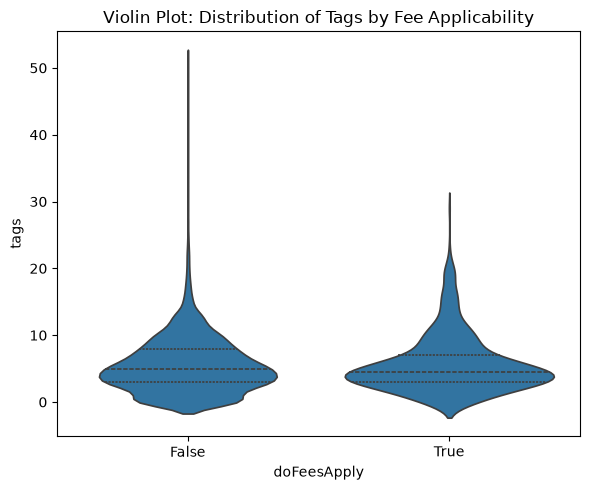

In [ ]:
# Create a violin plot to visualize the distribution of tags based on fee applicability
plt.figure(figsize = (6, 5))
sns.violinplot(data = eda_todo_df, x = 'doFeesApply', y = 'tags', inner = 'quartile')
plt.title('Violin Plot: Distribution of Tags by Fee Applicability')

plt.savefig('../figures/violinplot.png', dpi = 150, bbox_inches = 'tight')
plt.tight_layout()
plt.show()